# Benchmarking Network Inference Methods on Transient Data

This notebook compares multiple methods on transient biological time-series data across `n_reps` independent network topologies.


In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, roc_curve, precision_recall_curve, auc
from scipy.stats import spearmanr
import statsmodels.api as sm
import pysindy as ps

# Add project root to path
project_root = os.path.abspath('..')
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from inference_pipeline.data_generation.network_generator import generate_scale_free_W
from inference_pipeline.data_generation.simulator import simulate_realistic_pairs
import graph_tool.all as gt
from gene_expr import GeneExprBlockState


In [154]:
np.random.seed(42)
N = 10
M_train = 100  # sparse training data to encourage overfitting
M_test = 100
dt_sim = 0.005
dt_sample = 1.0
dt_meas = dt_sample  # measurement interval is the same as sampling interval
n_reps = 5

print(f"Generating {n_reps} datasets with different network topologies...")
datasets = []

for rep in range(n_reps):
    seed = 102 + rep
    W_true = generate_scale_free_W(N, m=1, seed=seed)
    W_true_binary = (W_true != 0).astype(int)
    
    s_train, _, _, _, _ = simulate_realistic_pairs(
        W_true, M=M_train, dt_sim=dt_sim, dt_sample=dt_sample, dt_meas=dt_meas, 
        D_base=0.02, mean_d=0.5, std_d=0.0, mean_V=2.0, std_V=0.0, seed=100+rep, t_window=(0.0, 3.0)
    )
    
    s_test, _, _, _, _ = simulate_realistic_pairs(
        W_true, M=M_test, dt_sim=dt_sim, dt_sample=dt_sample, dt_meas=dt_meas, 
        D_base=0.02, mean_d=0.5, std_d=0.0, mean_V=2.0, std_V=0.0, seed=200+rep, t_window=(0.0, 3.0)
    )
    
    X_train_in = np.array([pair[:, 0] for pair in s_train])
    X_train_out = np.array([pair[:, 1] for pair in s_train])
    dX_train = (X_train_out - X_train_in) / dt_meas
    
    X_test_in = np.array([pair[:, 0] for pair in s_test])
    X_test_out = np.array([pair[:, 1] for pair in s_test])
    dX_test = (X_test_out - X_test_in) / dt_meas
    
    datasets.append({
        'W_true': W_true, 'W_true_binary': W_true_binary,
        's_train': s_train, 's_test': s_test,
        'X_train_in': X_train_in, 'X_train_out': X_train_out, 'dX_train': dX_train,
        'X_test_in': X_test_in, 'X_test_out': X_test_out, 'dX_test': dX_test
    })

print("Done!")

results = {}

def calc_all_metrics(y_true_binary, y_true_continuous, y_scores, y_inferred_continuous=None):
    mask = ~np.eye(N, dtype=bool)
    y_true_b = y_true_binary[mask]
    y_s = y_scores[mask]
    
    fpr, tpr, _ = roc_curve(y_true_b, y_s)
    roc_auc = auc(fpr, tpr)
    
    precision, recall, _ = precision_recall_curve(y_true_b, y_s)
    pr_auc = auc(recall, precision)
    
    spearman_corr, _ = spearmanr(np.abs(y_true_continuous[mask]), np.abs(y_s))
    
    sign_acc = np.nan
    if y_inferred_continuous is not None:
        true_edges_mask = (y_true_b == 1)
        if np.any(true_edges_mask):
            true_signs = np.sign(y_true_continuous[mask][true_edges_mask])
            inf_signs = np.sign(y_inferred_continuous[mask][true_edges_mask])
            sign_acc = np.mean(true_signs == inf_signs)
    
    return fpr, tpr, roc_auc, precision, recall, pr_auc, spearman_corr, sign_acc


Generating 5 datasets with different network topologies...
Done!


## 1. Random Forest (dynGENIE3 equivalent)


In [155]:
print(f"Running Random Forest (dynGENIE3 equivalent) over {n_reps} replicates...")
method_res = {'AUPRC': [], 'AUROC': [], 'Train MSE': [], 'Test MSE': [], 'Spearman': [], 'Sign Accuracy': [], 'FPR': [], 'TPR': [], 'Precision': [], 'Recall': [], 'W': []}

W_rf_plot = None

for rep, ds in enumerate(datasets):
    X_train_in, X_train_out = ds['X_train_in'], ds['X_train_out']
    X_test_in, X_test_out = ds['X_test_in'], ds['X_test_out']
    
    rf_edge_scores = np.zeros((N, N))
    rf_train_preds = np.zeros_like(X_train_out)
    rf_test_preds = np.zeros_like(X_test_out)
    
    for i in range(N):
        mask = np.ones(N, dtype=bool)
        mask[i] = False
        rf = RandomForestRegressor(n_estimators=100, random_state=42+rep)
        rf.fit(X_train_in[:, mask], X_train_out[:, i])
        rf_edge_scores[i, mask] = rf.feature_importances_
        rf_train_preds[:, i] = rf.predict(X_train_in[:, mask])
        rf_test_preds[:, i] = rf.predict(X_test_in[:, mask])
        
    fpr, tpr, roc_auc, precision, recall, pr_auc, spearman, sign_acc = calc_all_metrics(
        ds['W_true_binary'], ds['W_true'], rf_edge_scores, y_inferred_continuous=None
    )
    
    if rep == 0: W_rf_plot = rf_edge_scores.copy()
        
    method_res['AUPRC'].append(pr_auc)
    method_res['AUROC'].append(roc_auc)
    method_res['Spearman'].append(spearman)
    method_res['Sign Accuracy'].append(sign_acc)
    method_res['Train MSE'].append(mean_squared_error(X_train_out, rf_train_preds))
    method_res['Test MSE'].append(mean_squared_error(X_test_out, rf_test_preds))
    method_res['FPR'].append(fpr)
    method_res['TPR'].append(tpr)
    method_res['Precision'].append(precision)
    method_res['Recall'].append(recall)
    method_res['W'].append(rf_edge_scores)

results['dynGENIE3 (RF)'] = method_res


Running Random Forest (dynGENIE3 equivalent) over 5 replicates...


--- Random Forest Results (Mean ± Std) ---
AUPRC: 0.4373 ± 0.1741
AUROC: 0.7641 ± 0.1217
Spearman: 0.2773 ± 0.1234
Train MSE: 0.0057 ± 0.0005
Test MSE: 0.0451 ± 0.0060


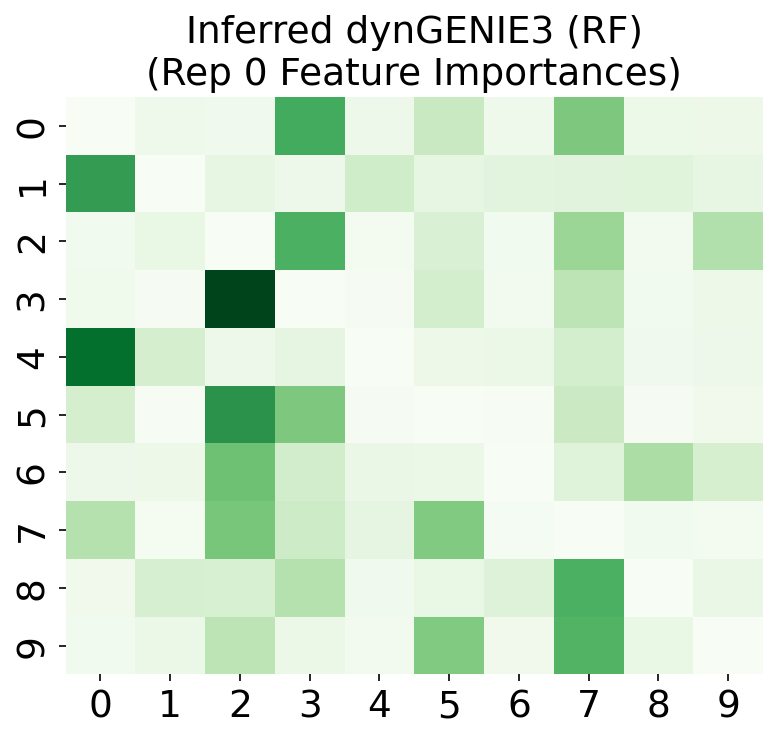

In [156]:
print("--- Random Forest Results (Mean ± Std) ---")
for metric in ['AUPRC', 'AUROC', 'Spearman', 'Train MSE', 'Test MSE']:
    print(f"{metric}: {np.nanmean(results['dynGENIE3 (RF)'][metric]):.4f} ± {np.nanstd(results['dynGENIE3 (RF)'][metric]):.4f}")

plt.figure(figsize=(6, 5))
np.fill_diagonal(W_rf_plot, 0)
sns.heatmap(W_rf_plot, cmap='Greens', cbar=False)
plt.title('Inferred dynGENIE3 (RF)\n(Rep 0 Feature Importances)')
plt.show()


## 2. Sparse ODE (Lasso)


In [157]:
print(f"Running Sparse ODE (Lasso) over {n_reps} replicates...")
method_res = {'AUPRC': [], 'AUROC': [], 'Train MSE': [], 'Test MSE': [], 'Spearman': [], 'Sign Accuracy': [], 'FPR': [], 'TPR': [], 'Precision': [], 'Recall': [], 'W': []}

W_lasso_plot = None

for rep, ds in enumerate(datasets):
    X_train_in, X_train_out, dX_train = ds['X_train_in'], ds['X_train_out'], ds['dX_train']
    X_test_in, X_test_out, dX_test = ds['X_test_in'], ds['X_test_out'], ds['dX_test']
    
    lasso_edge_scores = np.zeros((N, N))
    lasso_coefs_signed = np.zeros((N, N))
    lasso_train_preds = np.zeros_like(dX_train)
    lasso_test_preds = np.zeros_like(dX_test)
    
    for i in range(N):
        mask = np.ones(N, dtype=bool)
        mask[i] = False
        lasso = Lasso(alpha=0.01, random_state=42+rep)
        lasso.fit(X_train_in[:, mask], dX_train[:, i])
        lasso_edge_scores[i, mask] = np.abs(lasso.coef_)
        lasso_coefs_signed[i, mask] = lasso.coef_
        lasso_train_preds[:, i] = lasso.predict(X_train_in[:, mask])
        lasso_test_preds[:, i] = lasso.predict(X_test_in[:, mask])
        
    fpr, tpr, roc_auc, precision, recall, pr_auc, spearman, sign_acc = calc_all_metrics(
        ds['W_true_binary'], ds['W_true'], lasso_edge_scores, y_inferred_continuous=lasso_coefs_signed
    )
    
    if rep == 0: W_lasso_plot = lasso_edge_scores.copy()
    
    lasso_X_train_preds = X_train_in + lasso_train_preds * dt_meas
    lasso_X_test_preds = X_test_in + lasso_test_preds * dt_meas
    
    method_res['AUPRC'].append(pr_auc)
    method_res['AUROC'].append(roc_auc)
    method_res['Spearman'].append(spearman)
    method_res['Sign Accuracy'].append(sign_acc)
    method_res['Train MSE'].append(mean_squared_error(X_train_out, lasso_X_train_preds))
    method_res['Test MSE'].append(mean_squared_error(X_test_out, lasso_X_test_preds))
    method_res['FPR'].append(fpr)
    method_res['TPR'].append(tpr)
    method_res['Precision'].append(precision)
    method_res['Recall'].append(recall)
    method_res['W'].append(lasso_edge_scores)
results['Sparse ODE (Lasso)'] = method_res


Running Sparse ODE (Lasso) over 5 replicates...


--- Lasso Results (Mean ± Std) ---
AUPRC: 0.1089 ± 0.0260
AUROC: 0.5130 ± 0.0627
Spearman: 0.0119 ± 0.0771
Sign Accuracy: 0.2667 ± 0.0889
Train MSE: 0.0270 ± 0.0034
Test MSE: 0.0305 ± 0.0024


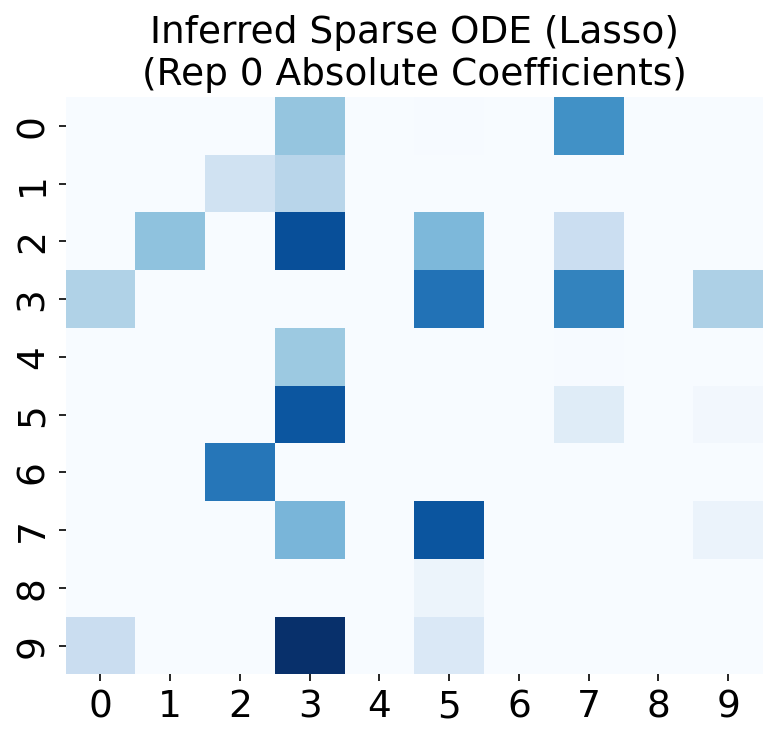

In [158]:
print("--- Lasso Results (Mean ± Std) ---")
for metric in ['AUPRC', 'AUROC', 'Spearman', 'Sign Accuracy', 'Train MSE', 'Test MSE']:
    print(f"{metric}: {np.nanmean(results['Sparse ODE (Lasso)'][metric]):.4f} ± {np.nanstd(results['Sparse ODE (Lasso)'][metric]):.4f}")

plt.figure(figsize=(6, 5))
np.fill_diagonal(W_lasso_plot, 0)
sns.heatmap(W_lasso_plot, cmap='Blues', cbar=False)
plt.title('Inferred Sparse ODE (Lasso)\n(Rep 0 Absolute Coefficients)')
plt.show()


## 3. Granger Causality (VAR-like F-test)


In [159]:
print(f"Running Granger Causality over {n_reps} replicates...")
method_res = {'AUPRC': [], 'AUROC': [], 'Train MSE': [], 'Test MSE': [], 'Spearman': [], 'Sign Accuracy': [], 'FPR': [], 'TPR': [], 'Precision': [], 'Recall': [], 'W': []}

W_gc_plot = None

for rep, ds in enumerate(datasets):
    X_train_in, X_train_out = ds['X_train_in'], ds['X_train_out']
    gc_edge_scores = np.zeros((N, N))

    for i in range(N):
        y = X_train_out[:, i]
        X_null = sm.add_constant(X_train_in[:, i])
        model_null = sm.OLS(y, X_null).fit()
        rss_null = np.sum(model_null.resid**2)
        
        for j in range(N):
            if i == j: continue
            X_alt = sm.add_constant(X_train_in[:, [i, j]])
            model_alt = sm.OLS(y, X_alt).fit()
            rss_alt = np.sum(model_alt.resid**2)
            
            # F-statistic for the nested model
            F = ((rss_null - rss_alt) / 1) / (rss_alt / (M_train - 3))
            gc_edge_scores[i, j] = F

    fpr, tpr, roc_auc, precision, recall, pr_auc, spearman, sign_acc = calc_all_metrics(
        ds['W_true_binary'], ds['W_true'], gc_edge_scores, y_inferred_continuous=None
    )
    
    if rep == 0: W_gc_plot = gc_edge_scores.copy()

    method_res['AUPRC'].append(pr_auc)
    method_res['AUROC'].append(roc_auc)
    method_res['Spearman'].append(spearman)
    method_res['Sign Accuracy'].append(sign_acc)
    method_res['Train MSE'].append(np.nan)
    method_res['Test MSE'].append(np.nan)
    method_res['FPR'].append(fpr)
    method_res['TPR'].append(tpr)
    method_res['Precision'].append(precision)
    method_res['Recall'].append(recall)
    method_res['W'].append(gc_edge_scores)
results['Granger Causality'] = method_res


Running Granger Causality over 5 replicates...


--- Granger Causality Results (Mean ± Std) ---
AUPRC: 0.4088 ± 0.0756
AUROC: 0.8239 ± 0.0397
Spearman: 0.3380 ± 0.0450


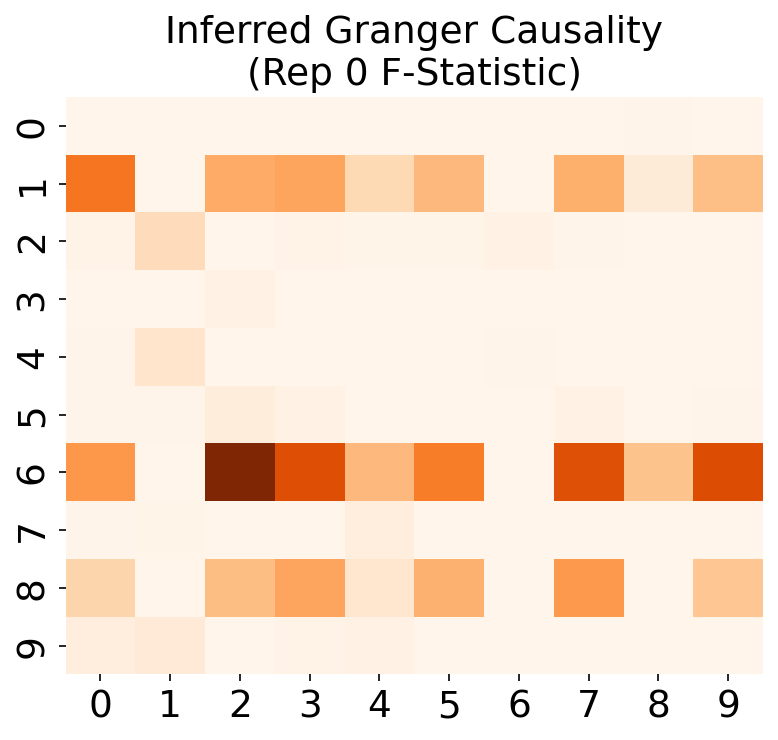

In [160]:
print("--- Granger Causality Results (Mean ± Std) ---")
for metric in ['AUPRC', 'AUROC', 'Spearman']:
    print(f"{metric}: {np.nanmean(results['Granger Causality'][metric]):.4f} ± {np.nanstd(results['Granger Causality'][metric]):.4f}")

plt.figure(figsize=(6, 5))
np.fill_diagonal(W_gc_plot, 0)
sns.heatmap(W_gc_plot, cmap='Oranges', cbar=False)
plt.title('Inferred Granger Causality\n(Rep 0 F-Statistic)')
plt.show()


## 4. PySINDy (STLSQ)


In [161]:
print(f"Running PySINDy over {n_reps} replicates...")
method_res = {'AUPRC': [], 'AUROC': [], 'Train MSE': [], 'Test MSE': [], 'Spearman': [], 'Sign Accuracy': [], 'FPR': [], 'TPR': [], 'Precision': [], 'Recall': [], 'W': []}

W_sindy_plot = None

for rep, ds in enumerate(datasets):
    X_train_in, X_train_out, dX_train = ds['X_train_in'], ds['X_train_out'], ds['dX_train']
    X_test_in, X_test_out, dX_test = ds['X_test_in'], ds['X_test_out'], ds['dX_test']

    model = ps.SINDy(optimizer=ps.STLSQ(threshold=0.01, alpha=0.01),
                     feature_library=ps.PolynomialLibrary(degree=1, include_interaction=False, include_bias=False))
    model.fit(X_train_in, t=dt_meas, x_dot=dX_train)

    sindy_coefs = model.coefficients()  # shape (N, N)
    sindy_coefs_signed = sindy_coefs.copy()
    np.fill_diagonal(sindy_coefs_signed, 0)
    sindy_edge_scores = np.abs(sindy_coefs_signed)

    fpr, tpr, roc_auc, precision, recall, pr_auc, spearman, sign_acc = calc_all_metrics(
        ds['W_true_binary'], ds['W_true'], sindy_edge_scores, y_inferred_continuous=sindy_coefs_signed
    )
    
    if rep == 0: W_sindy_plot = sindy_edge_scores.copy()

    sindy_train_preds = X_train_in + model.predict(X_train_in) * dt_meas
    sindy_test_preds = X_test_in + model.predict(X_test_in) * dt_meas

    method_res['AUPRC'].append(pr_auc)
    method_res['AUROC'].append(roc_auc)
    method_res['Spearman'].append(spearman)
    method_res['Sign Accuracy'].append(sign_acc)
    method_res['Train MSE'].append(mean_squared_error(X_train_out, sindy_train_preds))
    method_res['Test MSE'].append(mean_squared_error(X_test_out, sindy_test_preds))
    method_res['FPR'].append(fpr)
    method_res['TPR'].append(tpr)
    method_res['Precision'].append(precision)
    method_res['Recall'].append(recall)
    method_res['W'].append(sindy_coefs_signed)

results['PySINDy'] = method_res


Running PySINDy over 5 replicates...


--- PySINDy Results (Mean ± Std) ---
AUPRC: 0.3259 ± 0.1480
AUROC: 0.6584 ± 0.0634
Spearman: 0.1673 ± 0.0633
Sign Accuracy: 0.8222 ± 0.1133
Train MSE: 0.0355 ± 0.0097
Test MSE: 0.0460 ± 0.0116


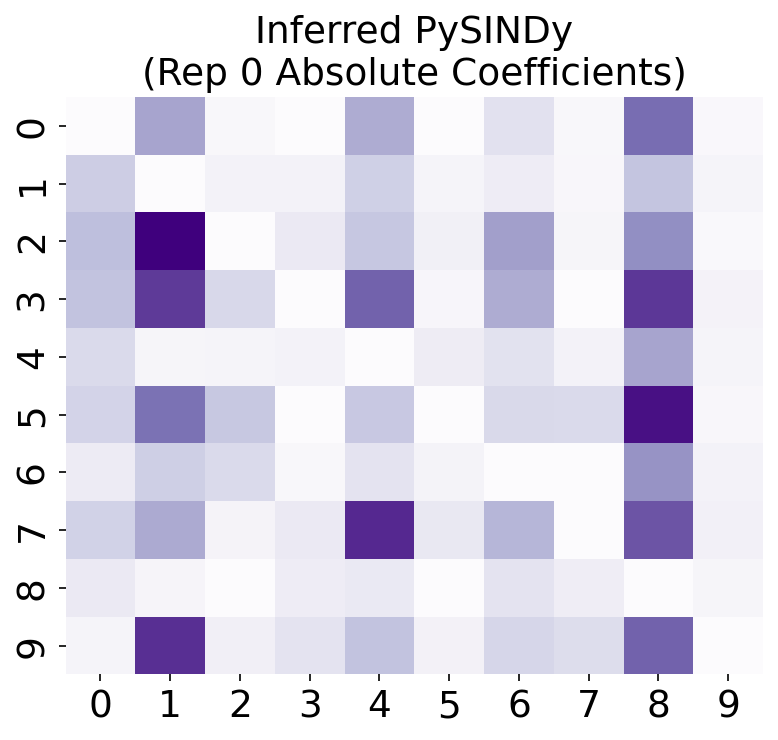

In [162]:
print("--- PySINDy Results (Mean ± Std) ---")
for metric in ['AUPRC', 'AUROC', 'Spearman', 'Sign Accuracy', 'Train MSE', 'Test MSE']:
    print(f"{metric}: {np.nanmean(results['PySINDy'][metric]):.4f} ± {np.nanstd(results['PySINDy'][metric]):.4f}")

plt.figure(figsize=(6, 5))
np.fill_diagonal(W_sindy_plot, 0)
sns.heatmap(W_sindy_plot, cmap='Purples', cbar=False)
plt.title('Inferred PySINDy\n(Rep 0 Absolute Coefficients)')
plt.show()


## 5. Graph-Tool SDE


In [163]:
print(f"Running Graph-Tool SDE over {n_reps} replicates...")
from inference_pipeline.inference.mcmc_engine import run_burn_in, run_posterior_sampling, compute_ensemble_stats

method_res = {'AUPRC': [], 'AUROC': [], 'Train MSE': [], 'Test MSE': [], 'Spearman': [], 'Sign Accuracy': [], 'FPR': [], 'TPR': [], 'Precision': [], 'Recall': [], 'W': []}
W_gt_plot = None

def sigmoid_np(x):
    x = np.clip(x, -50, 50)
    return 1.0 / (1.0 + np.exp(-x))

def predict_sde(X_in, W, d, V, dt_meas, dt_sim):
    n_steps = int(np.round(dt_meas / dt_sim))
    X_pred = X_in.copy()
    for _ in range(n_steps):
        drift = -d * X_pred + V * sigmoid_np(np.dot(X_pred, W.T))
        X_pred = np.maximum(X_pred + dt_sim * drift, 0.01)
    return X_pred

for rep, ds in enumerate(datasets):
    g_init = gt.Graph(directed=True)
    g_init.add_vertex(N)
    
    num_initial_edges = max(1, int(N * N * 0.05))
    possible_edges = [(u, v) for u in range(N) for v in range(N) if u != v]
    np.random.seed(42+rep)
    np.random.shuffle(possible_edges)
    for u, v in possible_edges[:num_initial_edges]:
        g_init.add_edge(u, v)

    initial_theta = [0.0, 0.0, np.log(0.05)]
    state = GeneExprBlockState(ds['s_train'], dt=dt_meas, g=g_init, state_args=dict(deg_corr=False), theta=initial_theta, use_em_likelihood=True)
    
    state = run_burn_in(state, n_burnin=50, theta_mode="global")
    W_ensemble, theta_ensemble = run_posterior_sampling(state, N, n_samples=100, delta_k=1, theta_mode="global")
    
    edge_probabilities, weight_mean, weight_std = compute_ensemble_stats(W_ensemble)
    gt_edge_scores = edge_probabilities * np.abs(weight_mean)
    
    fpr, tpr, roc_auc, precision, recall, pr_auc, spearman, sign_acc = calc_all_metrics(
        ds['W_true_binary'], ds['W_true'], gt_edge_scores, y_inferred_continuous=weight_mean
    )
    
    if rep == 0: W_gt_plot = gt_edge_scores.copy()
    
    theta_mean = np.mean(theta_ensemble, axis=0)
    d_mean, V_mean = np.exp(theta_mean[0]), np.exp(theta_mean[1])
    
    gt_train_preds = predict_sde(ds['X_train_in'], weight_mean, d_mean, V_mean, dt_meas, dt_sim)
    gt_test_preds = predict_sde(ds['X_test_in'], weight_mean, d_mean, V_mean, dt_meas, dt_sim)
    
    method_res['AUPRC'].append(pr_auc)
    method_res['AUROC'].append(roc_auc)
    method_res['Spearman'].append(spearman)
    method_res['Sign Accuracy'].append(sign_acc)
    method_res['Train MSE'].append(mean_squared_error(ds['X_train_out'], gt_train_preds))
    method_res['Test MSE'].append(mean_squared_error(ds['X_test_out'], gt_test_preds))
    method_res['FPR'].append(fpr)
    method_res['TPR'].append(tpr)
    method_res['Precision'].append(precision)
    method_res['Recall'].append(recall)
    method_res['W'].append(gt_edge_scores)

results['Graph-Tool SDE'] = method_res


Running Graph-Tool SDE over 5 replicates...

--- PHASE 1: Equilibration (50 sweeps) ---
Burn-in Sweep  1/50: Entropy = 2039.6483 (dS_topo = -2552.3247, dS_param = -1980.7551, moves = 7033)
Burn-in Sweep 10/50: Entropy = 1287.8429 (dS_topo =  48.9670, dS_param = -22.1252, moves = 6732)
Burn-in Sweep 20/50: Entropy = 874.5154 (dS_topo = -77.3163, dS_param =  -0.5206, moves = 6293)
Burn-in Sweep 30/50: Entropy = 811.0688 (dS_topo =  -0.7271, dS_param =  -1.1262, moves = 6803)
Burn-in Sweep 40/50: Entropy = 662.6221 (dS_topo =  -4.5403, dS_param =  -3.1205, moves = 5471)
Burn-in Sweep 50/50: Entropy = 550.6965 (dS_topo = -20.1180, dS_param =  -0.1227, moves = 8093)

--- PHASE 2: Sampling (100 samples, thinning 1) ---
Sample   1/100: Entropy = 563.7788
Sample  10/100: Entropy = 529.2623
Sample  20/100: Entropy = 587.6903
Sample  30/100: Entropy = 477.3265
Sample  40/100: Entropy = 491.5382
Sample  50/100: Entropy = 499.1403
Sample  60/100: Entropy = 551.8256
Sample  70/100: Entropy = 608.09

--- Graph-Tool SDE Results (Mean ± Std) ---
AUPRC: 0.8189 ± 0.0572
AUROC: 0.9578 ± 0.0358
Spearman: 0.4790 ± 0.0339
Sign Accuracy: 1.0000 ± 0.0000
Train MSE: 0.0416 ± 0.0092
Test MSE: 0.0448 ± 0.0085


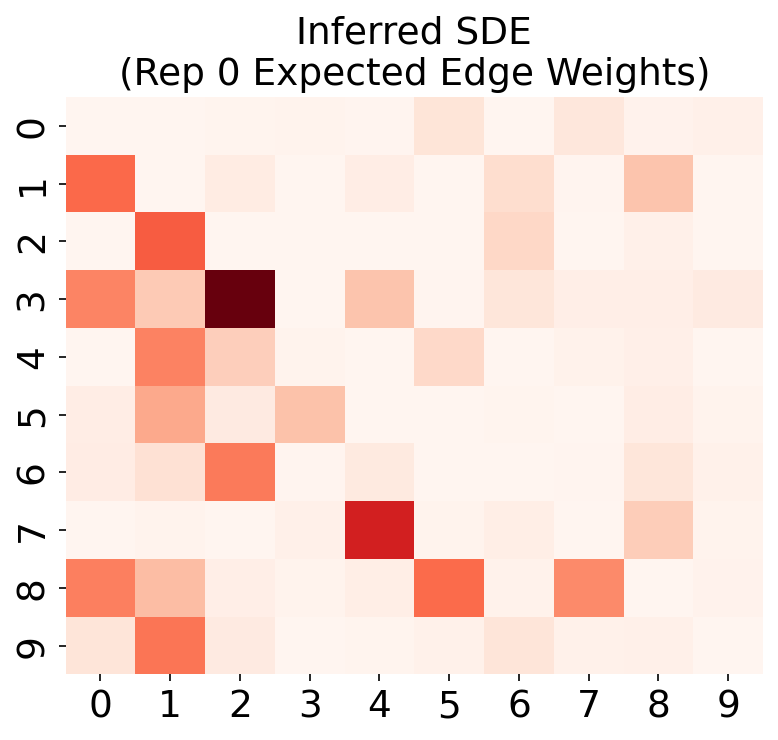

In [164]:
print("--- Graph-Tool SDE Results (Mean ± Std) ---")
for metric in ['AUPRC', 'AUROC', 'Spearman', 'Sign Accuracy', 'Train MSE', 'Test MSE']:
    print(f"{metric}: {np.nanmean(results['Graph-Tool SDE'][metric]):.4f} ± {np.nanstd(results['Graph-Tool SDE'][metric]):.4f}")

plt.figure(figsize=(6, 5))
np.fill_diagonal(W_gt_plot, 0)
sns.heatmap(W_gt_plot, cmap='Reds', cbar=False)
plt.title('Inferred SDE\n(Rep 0 Expected Edge Weights)')
plt.show()


## Save results

In [ ]:
# Save the results
np.savez("overfitting_experiment_results.npz", results=results, datasets=datasets)

## Final Comparison Plots (Aggregated over `n_reps`)


In [2]:
# Load the results
results, datasets = np.load("overfitting_experiment_results.npz", allow_pickle=True)['results'].item(), np.load("overfitting_experiment_results.npz", allow_pickle=True)['datasets'].tolist()

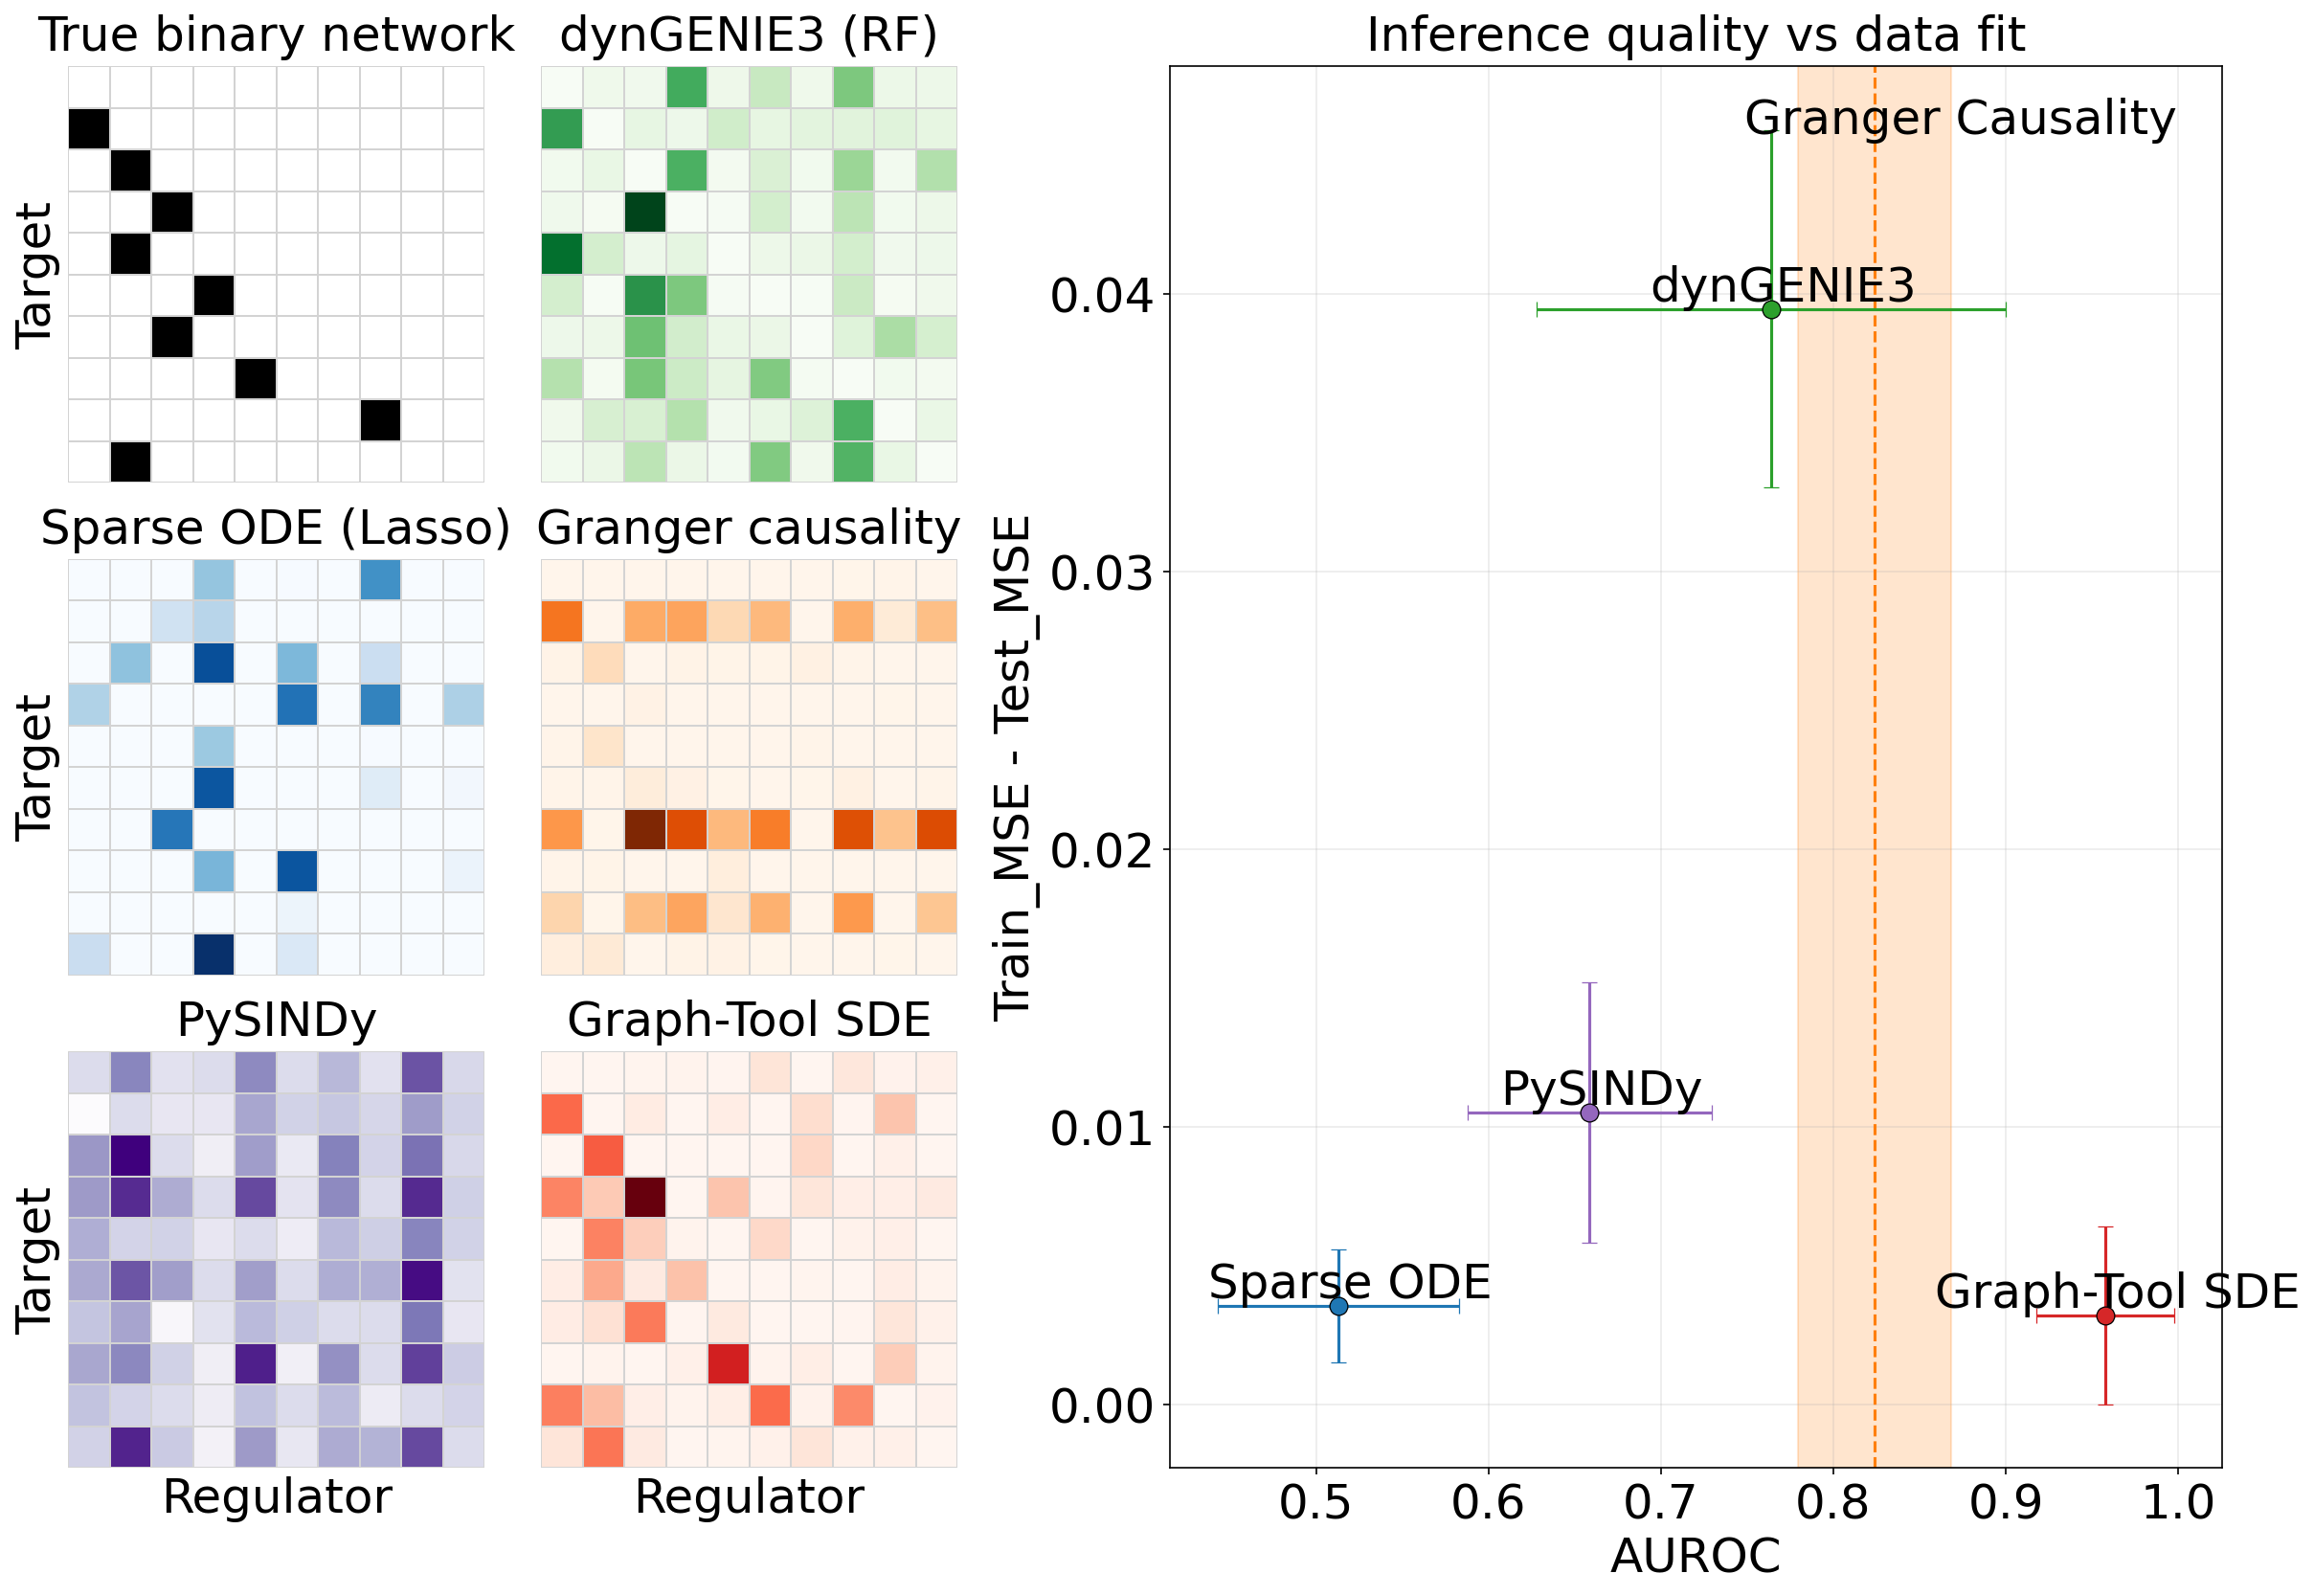

In [16]:
import matplotlib.gridspec as gridspec

fontsize = 24
plt.rcParams.update({
    "font.size": fontsize,
    "axes.titlesize": fontsize,
    "axes.labelsize": fontsize,
    "xtick.labelsize": fontsize,
    "ytick.labelsize": fontsize,
    "legend.fontsize": fontsize,
    "figure.dpi": 150,
    "savefig.dpi": 300,
})

methods = [
    "dynGENIE3 (RF)",
    "Sparse ODE (Lasso)",
    "Granger Causality",
    "PySINDy",
    "Graph-Tool SDE",
]

color_map = {
    "dynGENIE3 (RF)": "tab:green",
    "Sparse ODE (Lasso)": "tab:blue",
    "Granger Causality": "tab:orange",
    "PySINDy": "tab:purple",
    "Graph-Tool SDE": "tab:red",
}

fig = plt.figure(figsize=(16, 11), constrained_layout=True)
gs = gridspec.GridSpec(3, 3, figure=fig, width_ratios=[1, 1, 2.3])

axes = {
    "true": fig.add_subplot(gs[0, 0]),
    "rf": fig.add_subplot(gs[0, 1]),
    "lasso": fig.add_subplot(gs[1, 0]),
    "gc": fig.add_subplot(gs[1, 1]),
    "sindy": fig.add_subplot(gs[2, 0]),
    "gt": fig.add_subplot(gs[2, 1]),
    "scatter": fig.add_subplot(gs[:, 2]),
}

def plot_heat(ax, mat, title, cmap):
    m = np.asarray(mat).copy()
    np.fill_diagonal(m, 0)
    sns.heatmap(
        m,
        ax=ax,
        cmap=cmap,
        square=True,
        cbar=False,
        xticklabels=False,
        yticklabels=False,
        linewidths=0.2,
        linecolor="lightgray",
    )
    ax.set_title(title, pad=8)

index = 0
plot_heat(axes["true"], datasets[index]['W_true_binary'], "True binary network", "Greys")
plot_heat(axes["rf"], results["dynGENIE3 (RF)"]["W"][index], "dynGENIE3 (RF)", "Greens")
plot_heat(axes["lasso"], results["Sparse ODE (Lasso)"]["W"][index], "Sparse ODE (Lasso)", "Blues")
plot_heat(axes["gc"], results["Granger Causality"]["W"][index], "Granger causality", "Oranges")
plot_heat(axes["sindy"], results["PySINDy"]["W"][index], "PySINDy", "Purples")
plot_heat(axes["gt"], results["Graph-Tool SDE"]["W"][index], "Graph-Tool SDE", "Reds")

axes["true"].set_ylabel("Target")
axes["lasso"].set_ylabel("Target")
axes["sindy"].set_ylabel("Target")
axes["sindy"].set_xlabel("Regulator")
axes["gt"].set_xlabel("Regulator")

# Scatter: predictive fit vs inference quality, with 5 replicas per method
x_metric = "AUROC"
y_metric = "Train_MSE - Test_MSE"

def to_1d_array(x):
    arr = np.asarray(x)
    if arr.ndim == 0:
        return arr.reshape(1)
    return arr.ravel()

points = {}
for method in methods:
    res = results[method]

    x_vals = to_1d_array(res.get(x_metric, np.nan))
    train_vals = to_1d_array(res.get("Train MSE", np.nan))
    test_vals = to_1d_array(res.get("Test MSE", np.nan))

    n = min(len(x_vals), len(train_vals), len(test_vals))
    if n == 0 or np.isnan(x_vals[:n]).all() or np.isnan(train_vals[:n]).all() or np.isnan(test_vals[:n]).all():
        continue

    x_vals = x_vals[:n].astype(float)
    y_vals = test_vals[:n].astype(float) - train_vals[:n].astype(float)

    mask = np.isfinite(x_vals) & np.isfinite(y_vals)
    if not np.any(mask):
        continue

    x_vals = x_vals[mask]
    y_vals = y_vals[mask]

    points[method] = {
        "x_mean": np.mean(x_vals),
        "x_std": np.std(x_vals, ddof=1) if len(x_vals) > 1 else 0.0,
        "y_mean": np.mean(y_vals),
        "y_std": np.std(y_vals, ddof=1) if len(y_vals) > 1 else 0.0,
    }
    
for method, p in points.items():
    axes["scatter"].errorbar(
        x=p["x_mean"],
        y=p["y_mean"],
        xerr=p["x_std"],
        yerr=p["y_std"],
        fmt="o",
        ms=9,
        color=color_map[method],
        ecolor=color_map[method],
        elinewidth=1.5,
        capsize=4,
        markeredgecolor="black",
        markeredgewidth=0.6,
        label=method,
        zorder=3,
    )
    axes["scatter"].annotate(
        method.replace(" (RF)", "").replace(" (Lasso)", ""),
        (p["x_mean"], p["y_mean"]),
        textcoords="offset points",
        xytext=(6, 4),
        ha="center",
        fontsize=fontsize,
    )

#axes["scatter"].set_xlim([0.0, 1.0])
axes["scatter"].set_xlabel(x_metric)

if points:
    y_all = np.array([p["y_mean"] for p in points.values()], dtype=float)
    ymin = np.nanmin(y_all)
    ymax = np.nanmax(y_all)
    pad = 0.15 * max(abs(ymin), abs(ymax), 1e-8)
    #axes["scatter"].set_ylim([ymin - pad, ymax + pad])
else:
    pass
    #axes["scatter"].set_ylim([0, 1])

axes["scatter"].set_ylabel(y_metric)
axes["scatter"].set_title("Inference quality vs data fit", pad=8)
axes["scatter"].grid(True, alpha=0.25, zorder=0)

# Add Granger Causality reference band
if "Granger Causality" in results and "AUROC" in results["Granger Causality"]:
    gc_auroc = results["Granger Causality"]["AUROC"]
    if np.isscalar(gc_auroc):
        gc_auroc = np.atleast_1d(gc_auroc)
    else:
        gc_auroc = np.asarray(gc_auroc).ravel()
    
    gc_auroc = gc_auroc[np.isfinite(gc_auroc)]
    if len(gc_auroc) > 0:
        gc_x_mean = np.mean(gc_auroc)
        gc_x_std = np.std(gc_auroc, ddof=1) if len(gc_auroc) > 1 else 0.0
        axes["scatter"].axvspan(
            gc_x_mean - gc_x_std,
            gc_x_mean + gc_x_std,
            alpha=0.2,
            color="tab:orange",
            label="Granger Causality (±1σ)",
        )
        axes["scatter"].axvline(
            x=gc_x_mean,
            color="tab:orange",
            linestyle="--",
            linewidth=1.5,
        )
        axes["scatter"].text(
            gc_x_mean+0.05,
            axes["scatter"].get_ylim()[1] * 0.95,
            "Granger Causality",
            ha="center",
            fontsize=fontsize,
            color="k"
        )

plt.savefig("../images/inference_quality_vs_fit.png", dpi=300, bbox_inches="tight")
